# Vaizdų atpažinimas: tikros ir DI sugeneruotos naujienų nuotraukos

Nustatoma, ar naujienų nuotrauka tikra, ar sugeneruota DI. Naudojamas MiRAGeNews rinkinys (Huang et al., 2024): tikros nuotraukos iš naujienų leidėjų, netikros sugeneruotos pagal naujienų antraštes. Iš anksto išmokytas CLIP ViT-L/14 paverčia vaizdą požymių vektoriumi, o ant jo mokoma logistinė regresija.

In [1]:
import os, io
os.environ["KERAS_BACKEND"] = "torch"  # turi buti nustatyta pries importuojant keras
import numpy as np, pandas as pd, matplotlib.pyplot as plt, joblib, keras, keras_hub, torch
from pathlib import Path
from PIL import Image
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, ConfusionMatrixDisplay

DATA = Path("../data/mirage_news")
FIG = Path("../report/figures"); FIG.mkdir(parents=True, exist_ok=True)
MODELS = Path("../models")

## 1. Duomenys
Mokymui 10 000 vaizdų, validacijai 2 500, trys testo rinkiniai po 500, kiekviename pusė tikrų (`label` 0) ir pusė sugeneruotų (`label` 1).

| Rinkinys | Tikros nuotraukos | Sugeneruoti vaizdai | Ar matyta mokant |
|---|---|---|---|
| train, validation | The New York Times | Midjourney | |
| test1 | The New York Times | Midjourney | tas pats šaltinis |
| test4 | BBC | Stable Diffusion XL | kitas leidėjas ir generatorius |
| test5 | CNN | Stable Diffusion XL | kitas leidėjas ir generatorius |

In [2]:
def load(name):
    df = pd.read_parquet(DATA / f"{name}-00000-of-00001.parquet", columns=["image", "label"])
    return [d["bytes"] for d in df["image"]], df["label"].to_numpy()

def open_rgb(b):
    return Image.open(io.BytesIO(b)).convert("RGB")  # keli vaizdai PNG arba nespalvoti

train_x, train_y = load("train")
SETS = {"validation": "validation", "test1 NYT / Midjourney": "test1_nyt_mj",
        "test4 BBC / SDXL": "test4_bbc_sdxl", "test5 CNN / SDXL": "test5_cnn_sdxl"}
sets = {name: load(file) for name, file in SETS.items()}

Patikrinta, ar tikri ir netikri vaizdai skiriasi ne turiniu, o failu, nes tokį skirtumą modelis galėtų išmokti vietoj generatoriaus požymių.

In [3]:
def jpeg_table(im):  # JPEG kvantavimo lenteles vidurkis: kuo didesnis, tuo stipriau suspausta
    return np.mean(im.quantization[0]) if im.format == "JPEG" else np.nan

rows, tables = {}, {}
for name, (x, y) in {"train": (train_x, train_y), **sets}.items():
    ims = [Image.open(io.BytesIO(b)) for b in x]  # skaito tik antraste, ne visa vaizda
    q = tables[name] = np.array([jpeg_table(im) for im in ims])  # lenteliu prireiks ir klaidu analizei
    size = pd.Series([im.size for im in ims])
    rows[name] = {"images": len(y), "fake share": y.mean(),
                  "real: JPEG table mean (median)": np.nanmedian(q[y == 0]), "fake: JPEG table mean (median)": np.nanmedian(q[y == 1]),
                  "fake: distinct JPEG tables": len(np.unique(q[y == 1])),
                  "real: most common size": size[y == 0].mode()[0], "fake: most common size": size[y == 1].mode()[0]}
pd.DataFrame(rows).T

,images,fake share,real: JPEG table mean (median),fake: JPEG table mean (median),fake: distinct JPEG tables,real: most common size,fake: most common size
train,10000,0.5,44.8125,29.03125,1,"(600, 400)","(600, 400)"
validation,2500,0.5,44.8125,29.03125,1,"(600, 400)","(600, 400)"
test1 NYT / Midjourney,500,0.5,44.8125,29.03125,1,"(600, 330)","(600, 330)"
test4 BBC / SDXL,500,0.5,23.078125,29.03125,1,"(1024, 576)","(1024, 1024)"
test5 CNN / SDXL,500,0.5,29.03125,29.03125,1,"(1100, 619)","(1024, 1024)"


Visi sugeneruoti vaizdai išsaugoti su ta pačia JPEG kvantavimo lentele, o tikros nuotraukos turi kiekvieno leidėjo suspaudimą, todėl modelis galėtų išmokti JPEG nustatymą (tą patį aprašė Grommelt et al., 2024). Dėl to mokymo vaizdai suspaudžiami iš naujo atsitiktine kokybe. Vaizdų dydis ir proporcijos klasių neišduoda, nes CLIP iškerpa centrinį kvadratą.

Mokymo vaizdų pavyzdžiai (viršuje tikros nuotraukos, apačioje sugeneruoti vaizdai):

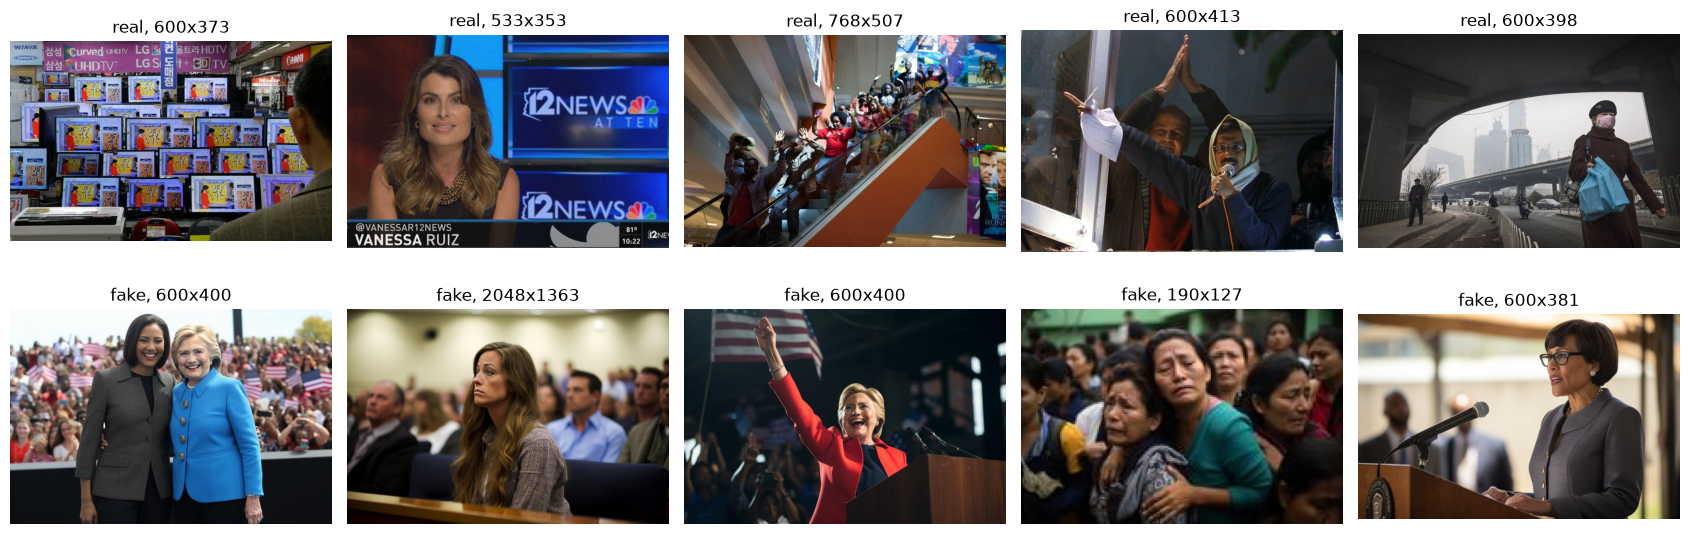

In [4]:
rng = np.random.default_rng(0)
fig, axes = plt.subplots(2, 5, figsize=(17, 6))
for row, label in zip(axes, (0, 1)):
    for ax, j in zip(row, rng.choice(np.flatnonzero(train_y == label), 5, replace=False)):
        im = open_rgb(train_x[j])
        ax.imshow(im); ax.set_title(f"{('real', 'fake')[label]}, {im.width}x{im.height}"); ax.axis("off")
plt.tight_layout(); plt.savefig(FIG / "img_examples.png", dpi=110); plt.show()

## 2. Duomenų paruošimas
Iš vaizdo iškerpamas centrinis kvadratas, sumažinamas iki 224 × 224 ir spalvos sunormuojamos kaip mokant CLIP. Mokymo vaizdai prieš tai suspaudžiami iš naujo atsitiktine JPEG kokybe (60-100), validacijos ir testo vaizdai nekeičiami. Požymių vektoriai sunormuojami iki ilgio 1.

In [5]:
def resave(im, rng):  # visi netikri saugoti vienodu JPEG nustatymu, todel mokymo vaizdus suspaudziam is naujo atsitiktine kokybe
    buf = io.BytesIO()
    im.save(buf, "JPEG", quality=int(rng.integers(60, 101)))
    return Image.open(buf).convert("RGB")

## 3. Modelis

CLIP ViT-L/14 išmokytas su 400 mln. vaizdų ir aprašymų porų. Jo vaizdų dalis lieka užšaldyta ir paverčia vaizdą 768 skaičių vektoriumi, ant kurio mokoma logistinė regresija.

| Dalis | Ką daro |
|---|---|
| Įvestis | 224 × 224 RGB vaizdas |
| Dalijimas į gabalus | 256 gabalai po 14 × 14 pikselių ir vienas bendras vaizdo vektorius |
| 24 transformerio sluoksniai | savęs dėmesys (16 galvų) ir dviejų sluoksnių tinklas (QuickGELU) |
| Projekcija | 768 skaičių požymių vektorius |
| Logistinė regresija | 768 svoriai ir poslinkis, sigmoidė duoda tikimybę, kad vaizdas sugeneruotas |

Tinklas, mokytas atskirti vieno generatoriaus vaizdus, su nematytais generatoriais klysta, o CLIP požymiai tam nebuvo mokyti, todėl mažiau prisitaiko prie vieno generatoriaus (Ojha et al., 2023). C parenkamas pagal validacijos accuracy iš 0,1, 1, 10 ir 100.

In [6]:
CLIP_FEATS, CLIP_LR = MODELS / "clip_vit_l14_features.npz", MODELS / "clip_logreg.joblib"
if CLIP_FEATS.exists():
    feats = dict(np.load(CLIP_FEATS))
else:
    clip = keras_hub.models.CLIPBackbone.from_preset("hf://keras/clip_vit_large_patch14")  # ~1,7 GB, atsisiuncia tik pirma karta
    to_clip = keras_hub.layers.CLIPImageConverter.from_preset("hf://keras/clip_vit_large_patch14")  # centrinis kvadratas, 224x224, CLIP spalvu normavimas

    def embed(x, train=False):
        rng, out = np.random.default_rng(0), []
        for i in range(0, len(x), 32):
            ims = [open_rgb(b) for b in x[i:i + 32]]
            if train:
                ims = [resave(im, rng) for im in ims]
            batch = keras.ops.stack([to_clip(np.asarray(im, dtype="float32")) for im in ims])
            with torch.no_grad():  # tik skaiciuojam, gradientu nereikia, kitaip netelpa i GPU
                out.append(keras.ops.convert_to_numpy(clip.get_vision_embeddings(batch)))
        e = np.concatenate(out)
        return e / np.linalg.norm(e, axis=1, keepdims=True)

    feats = {"train": embed(train_x, train=True), **{file: embed(sets[name][0]) for name, file in SETS.items()}}
    np.savez(CLIP_FEATS, **feats)
    del clip

if CLIP_LR.exists():
    logreg = joblib.load(CLIP_LR)
else:
    fits = {c: LogisticRegression(C=c, max_iter=5000).fit(feats["train"], train_y) for c in (0.1, 1, 10, 100)}
    acc = {c: round(m.score(feats["validation"], sets["validation"][1]), 4) for c, m in fits.items()}
    print(acc)
    logreg = fits[max(acc, key=acc.get)]  # stipruma renkames pagal validacija
    joblib.dump(logreg, CLIP_LR)
print("C =", logreg.C, " train features:", feats["train"].shape, " train accuracy:", round(logreg.score(feats["train"], train_y), 4))

C = 100  train features: (10000, 768)  train accuracy: 0.9902


Parinkta C = 100 (validacijos accuracy 98,96 %), nors C = 1, 10 ir 100 skiriasi mažiau nei 0,3 procento. Mokymo accuracy (99,0 %) toks pat kaip validacijos, taigi modelis mokymo vaizdų neįsiminė.

## 4. Rezultatai
Riba, nuo kurios vaizdas laikomas „fake“, parenkama pagal validacijos accuracy ir taikoma testo rinkiniams nekeičiant.

In [7]:
preds = pd.concat([pd.DataFrame({"split": name, "image": np.arange(len(y)), "label": y,
                                 "p_fake": logreg.predict_proba(feats[SETS[name]])[:, 1]}) for name, (_, y) in sets.items()],
                  ignore_index=True)

val = preds[preds["split"] == "validation"]
cutoff = max(np.round(np.arange(0.05, 0.96, 0.01), 2), key=lambda t: ((val["p_fake"] >= t) == val["label"]).mean())  # riba tik pagal validacija
preds["fake"] = (preds["p_fake"] >= cutoff).astype(int)
print("cut-off:", cutoff)

cut-off: 0.67


Recall rodo, kokią dalį sugeneruotų vaizdų modelis pagavo, „real kept“ - kokią dalį tikrų nuotraukų paliko tikromis. Paskutinis stulpelis rodo accuracy su riba 0,5.

In [8]:
def scores(g):
    y, p = g["label"], g["fake"]
    return pd.Series({"accuracy": accuracy_score(y, p), "precision": precision_score(y, p, zero_division=0),
                      "recall (fake caught)": recall_score(y, p), "real kept": recall_score(1 - y, 1 - p), "F1": f1_score(y, p),
                      "accuracy at 0.5": accuracy_score(y, g["p_fake"] >= 0.5)})

table = preds.groupby("split", sort=False).apply(scores).round(3)
table

,accuracy,precision,recall (fake caught),real kept,F1,accuracy at 0.5
split,,,,,,
validation,0.990,0.994,0.986,0.994,0.990,0.990
test1 NYT / Midjourney,0.996,1.000,0.992,1.000,0.996,0.996
test4 BBC / SDXL,0.820,0.776,0.900,0.740,0.833,0.804
test5 CNN / SDXL,0.750,0.678,0.952,0.548,0.792,0.728


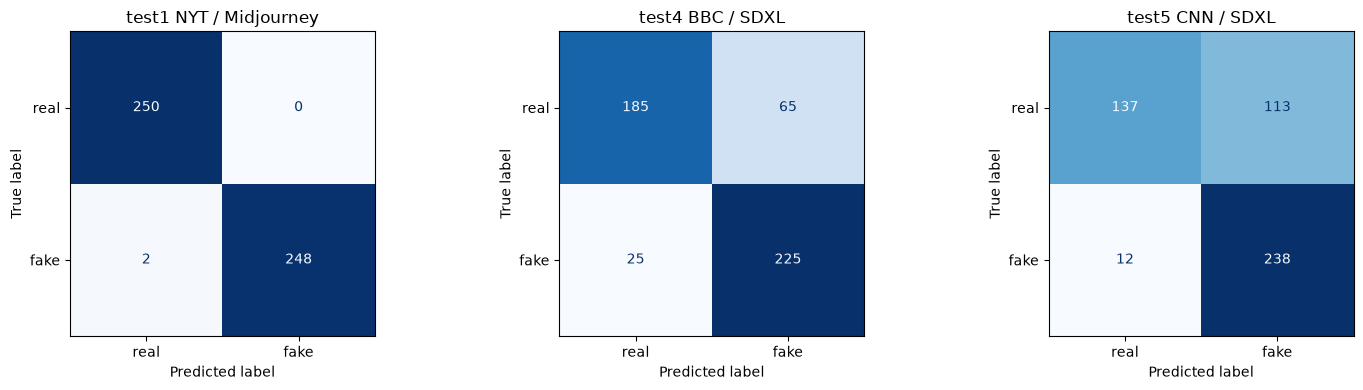

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, split in zip(axes, list(SETS)[1:]):
    g = preds[preds["split"] == split]
    ConfusionMatrixDisplay.from_predictions(g["label"], g["fake"], display_labels=["real", "fake"], cmap="Blues", colorbar=False, ax=ax)
    ax.set_title(split)
plt.tight_layout(); plt.savefig(FIG / "img_confusion.png", dpi=120); plt.show()

Parinkta riba 0,67: test1 accuracy nepakito, test4 ir test5 pakilo 1,6 ir 2,2 procento.

Tame pačiame šaltinyje (test1) modelis pasiekė 99,6 % ir suklydo 2 kartus iš 500, panašiai kaip MiRAGeNews autorių linijinis modelis (97,6 %). Midjourney vaizdai turi atpažįstamą stilių, todėl juos atskirti nuo NYT nuotraukų lengva.

Su kitais leidėjais ir generatoriumi accuracy krenta iki 82,0 % (BBC) ir 75,0 % (CNN). Modelis pagauna daugumą SDXL vaizdų (90,0 % ir 95,2 %), bet tikromis palieka tik 74,0 % BBC ir 54,8 % CNN nuotraukų, panašiai kaip MiRAGeNews autorių rezultatai (77,2 % ir 74,2 %).

## 5. Klaidos
Klaidos, kuriose modelis buvo labiausiai įsitikinęs.

errors per test set: {'test1 NYT / Midjourney': 2, 'test4 BBC / SDXL': 90, 'test5 CNN / SDXL': 125}
of them real photos called fake: {'test4 BBC / SDXL': 65, 'test5 CNN / SDXL': 113}


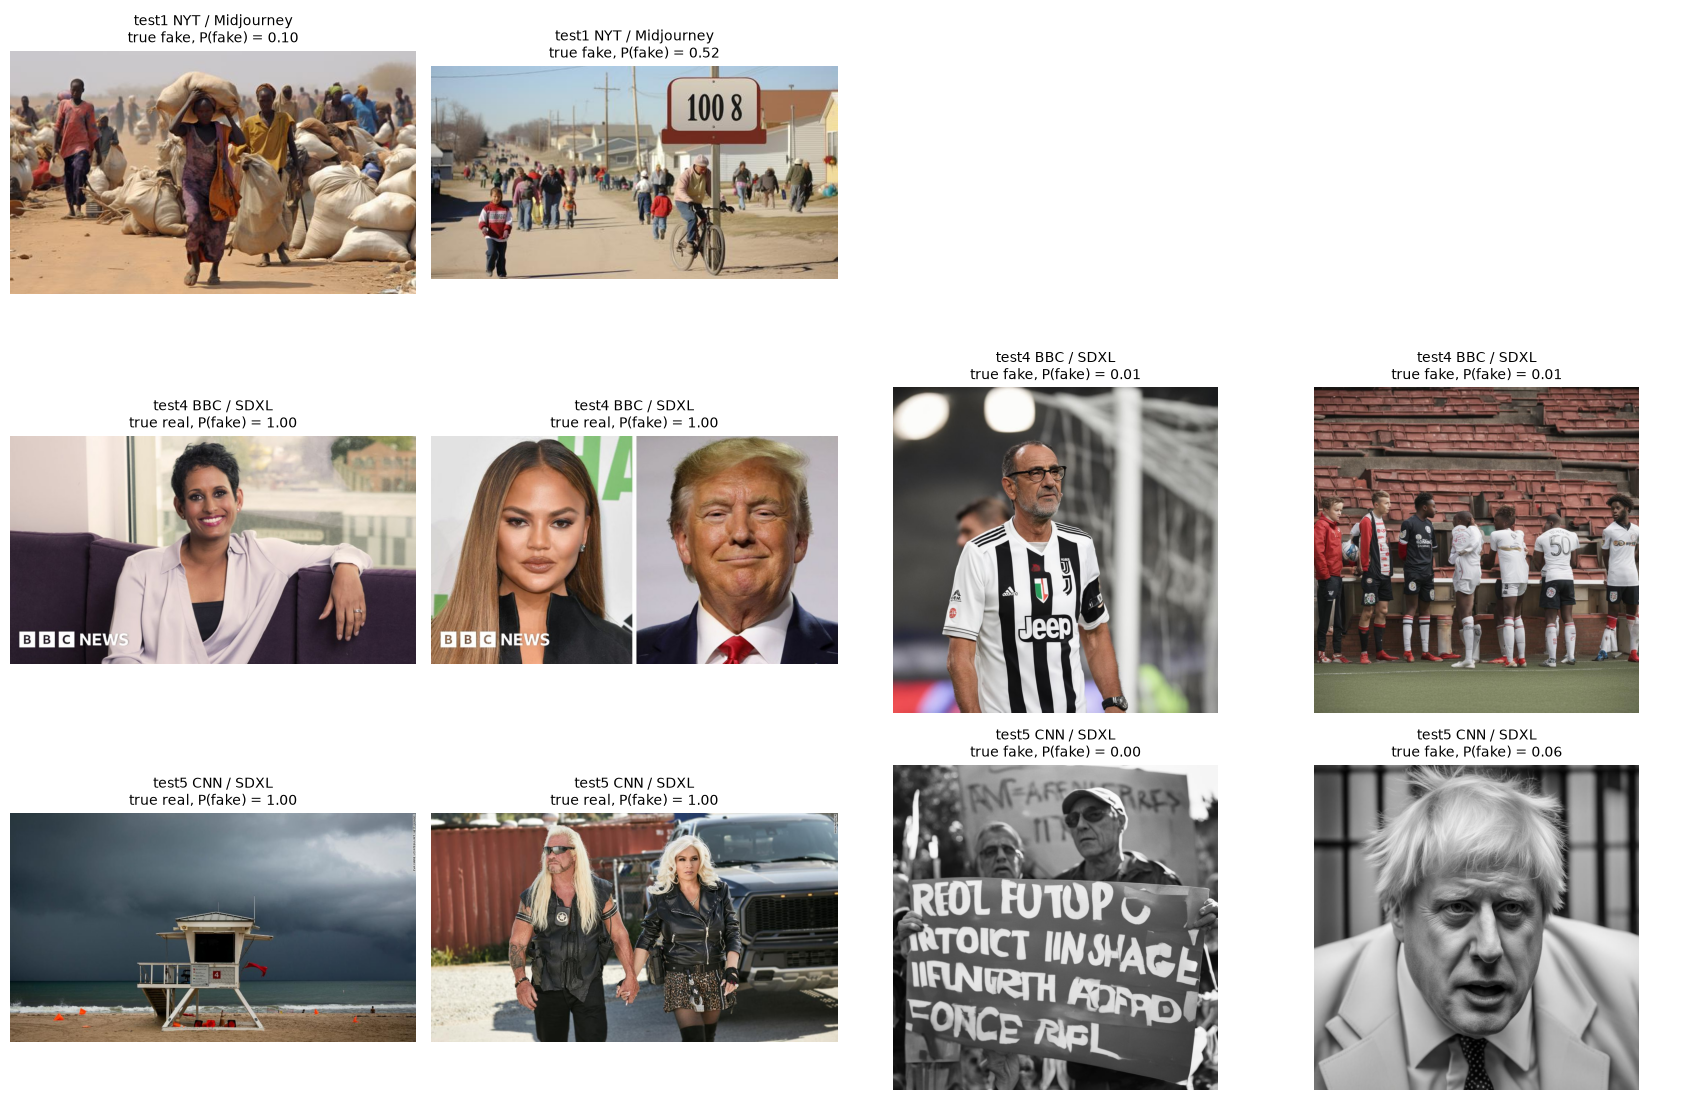

In [10]:
wrong = preds[(preds["split"] != "validation") & (preds["fake"] != preds["label"])]
wrong = wrong.assign(sureness=(wrong["p_fake"] - cutoff).abs()).sort_values("sureness", ascending=False)
picked = wrong.groupby(["split", "label"], sort=False).head(2).sort_values(["split", "label"])
print("errors per test set:", wrong.groupby("split").size().to_dict())
print("of them real photos called fake:", wrong[wrong["label"] == 0].groupby("split").size().to_dict())

splits = picked["split"].unique()
fig, axes = plt.subplots(len(splits), 4, figsize=(17, 3.7 * len(splits)))
for row, split in zip(axes, splits):  # viena eilute vienam rinkiniui, net jei klaidu maziau nei 4
    for ax in row: ax.axis("off")
    for ax, (_, r) in zip(row, picked[picked["split"] == split].iterrows()):
        ax.imshow(open_rgb(sets[split][0][r["image"]]))
        ax.set_title(f"{split}\ntrue {('real', 'fake')[r['label']]}, P(fake) = {r['p_fake']:.2f}", fontsize=10)
plt.tight_layout(); plt.savefig(FIG / "img_errors.png", dpi=110); plt.show()

Test4 ir test5 rinkiniuose dalis tikrų nuotraukų turi tą pačią JPEG lentelę kaip sugeneruoti vaizdai. Jei modelis remiasi JPEG nustatymu, šias nuotraukas jis dažniau palaikys sugeneruotomis:

In [11]:
fake_table = tables["train"][train_y == 1][0]
real = preds[(preds["label"] == 0) & preds["split"].str.startswith(("test4", "test5"))].copy()
real["same JPEG table as fakes"] = [tables[s][i] == fake_table for s, i in zip(real["split"], real["image"])]
real.groupby(["split", "same JPEG table as fakes"]).agg(photos=("fake", "size"), called_fake=("fake", "mean")).round(3)

photos  called_fake
split            same JPEG table as fakes                     
test4 BBC / SDXL False                        171        0.211
                 True                          79        0.367
test5 CNN / SDXL False                         32        0.219
                 True                         218        0.486

Tokios nuotraukos palaikomos sugeneruotomis dažniau (test4 36,7 % prieš 21,1 %, test5 48,6 % prieš 21,9 %), bet test4 jos visos yra 624 pikselių pločio, todėl tai gali būti kitokio tipo nuotraukos, o 224 × 224 vaizde JPEG pėdsakų lieka mažai. Vien JPEG nustatymu šio skirtumo paaiškinti negalima.

### Dažniausios klaidos

Dauguma klaidų atsiranda su kitais leidėjais: test1 rinkinyje modelis suklysta 2 kartus, test4 - 90, test5 - 125, daugiausia palaikydamas tikras BBC ir CNN nuotraukas sugeneruotomis (65 ir 113). Modelis išmoko atskirti NYT nuo Midjourney, todėl kitų leidėjų nuotraukos jam atrodo kaip „ne NYT“.

Labiausiai įsitikinęs (P(fake) = 1,00) modelis klysta su išblizgintomis tikromis nuotraukomis: pozuojantys žmonės, švarus apšvietimas, logotipai, koliažai, dramatiškas dangus. Taip atrodo daugelis Midjourney vaizdų.

Tikrais palaikomi nespalvoti SDXL vaizdai ir sporto scenos. Mokymo duomenyse nespalvoti vaizdai apie 4 kartus dažnesni tarp tikrų nuotraukų, o sujauktų plakato raidžių CLIP nepastebi, nes jo požymiai apibūdina turinį, o ne raidžių formą. Abi test1 klaidos yra įprastos sugeneruotos scenos be keistų detalių.

Sumažinus vaizdą iki 224 × 224 dingsta smulkūs generatoriaus pėdsakai, todėl modelis remiasi bendru stiliumi, kuris priklauso nuo generatoriaus.

## 6. Palyginimas su CNN

Palyginimui mokyti du MobileNetV2 tinklai (ImageNet svoriai): vienas su vaizdais, sumažintais iki 224 × 224, kitas su originalia raiška.

| Modelis | Validacija | test1 NYT / Midjourney | test4 BBC / SDXL | test5 CNN / SDXL |
|---|---|---|---|---|
| MobileNetV2, 224 × 224 | 86,1 % | 83,8 % | 58,2 % | 59,4 % |
| MobileNetV2, originali raiška | 92,3 % | 91,2 % | 64,2 % | 67,8 % |
| CLIP ViT-L/14 + logistinė regresija | 99,0 % | 99,6 % | 82,0 % | 75,0 % |

Originali raiška MobileNetV2 tinklui padėjo, nes išlieka smulkūs generatoriaus pėdsakai, bet abu tinklai su nematytais leidėjais klydo taip pat kaip CLIP, tik dažniau.

## 7. Išvados
Užšaldytas CLIP ViT-L/14 su logistine regresija Midjourney vaizdus tarp NYT nuotraukų atpažįsta 99,6 % tikslumu, o su kitais leidėjais ir SDXL - 82,0 % ir 75,0 %, ir lenkia MobileNetV2 tinklus. Su nematytais leidėjais jis dažniausiai palaiko išblizgintas tikras nuotraukas sugeneruotomis, nes išmoko vieno generatoriaus ir vieno leidėjo skirtumus. Norint atpažinti sugeneruotus vaizdus apskritai, reikėtų kelių generatorių ir leidėjų mokymo duomenų.